In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import shap
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 数据导入
data = pd.read_csv('Churn.csv')

# 特征和目标变量分离
X = data.drop(['Exited'], axis=1)
y = data['Exited']
original_X = X.copy()

# 数据归一化
scaler = MinMaxScaler()
X = scaler.fit_transform(X)
# 数据集划分
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 数据标准化
# scaler = MinMaxScaler()
# x_train_scaled = scaler.fit_transform(x_train)
# x_test_scaled = scaler.transform(x_test)

# 构建前馈神经网络模型
model = Sequential()

model.add(Dense(64, input_dim=x_train.shape[1], activation='relu'))
model.add(Dense(32, input_dim=x_train.shape[1], activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

# 编译模型
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 训练模型
model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

# 预测
y_pred = model.predict(x_test)

# # 使用SHAP解释模型
# explainer = shap.KernelExplainer(model.predict, x_train_scaled)
# shap_values = explainer.shap_values(x_test_scaled)

# # 可视化第一个样本的SHAP值
# shap.initjs()
# shap.force_plot(explainer.expected_value[0], shap_values[0][0], x_test.iloc[0])


Epoch 1/10
3301/3301 ━━━━━━━━━━━━━━━━━━━━ 2s 406us/step - accuracy: 0.8340 - loss: 0.3829 - val_accuracy: 0.8488 - val_loss: 0.3538
Epoch 2/10
3301/3301 ━━━━━━━━━━━━━━━━━━━━ 1s 382us/step - accuracy: 0.8486 - loss: 0.3559 - val_accuracy: 0.8483 - val_loss: 0.3613
Epoch 3/10
3301/3301 ━━━━━━━━━━━━━━━━━━━━ 1s 387us/step - accuracy: 0.8516 - loss: 0.3515 - val_accuracy: 0.8515 - val_loss: 0.3517
Epoch 4/10
3301/3301 ━━━━━━━━━━━━━━━━━━━━ 1s 377us/step - accuracy: 0.8497 - loss: 0.3526 - val_accuracy: 0.8514 - val_loss: 0.3519
Epoch 5/10
3301/3301 ━━━━━━━━━━━━━━━━━━━━ 1s 374us/step - accuracy: 0.8499 - loss: 0.3534 - val_accuracy: 0.8506 - val_loss: 0.3530
Epoch 6/10
3301/3301 ━━━━━━━━━━━━━━━━━━━━ 1s 377us/step - accuracy: 0.8490 - loss: 0.3533 - val_accuracy: 0.8508 - val_loss: 0.3505
Epoch 7/10
3301/3301 ━━━━━━━━━━━━━━━━━━━━ 1s 385us/step - accuracy: 0.8514 - loss: 0.3518 - val_accuracy: 0.8508 - val_loss: 0.3505
Epoch 8/10
3301/3301 ━━━━━━━━━━━━━━━━━━━━ 1s 382us/step - accuracy: 0.8528 -

In [2]:
from sklearn.metrics import f1_score,mean_squared_error,mean_squared_log_error,make_scorer

f1 = f1_score(y_test, y_pred.round())
f1

0.5974025974025974

In [3]:
import shap
import time
s = time.time()

explainer = shap.PermutationExplainer(model,x_train)
shap_values = explainer.shap_values(x_test)
feature_names = original_X.columns.tolist()

# Visualize SHAP values
# shap.summary_plot(shap_values[0], x_test)


PermutationExplainer explainer: 33008it [03:07, 168.52it/s]                           


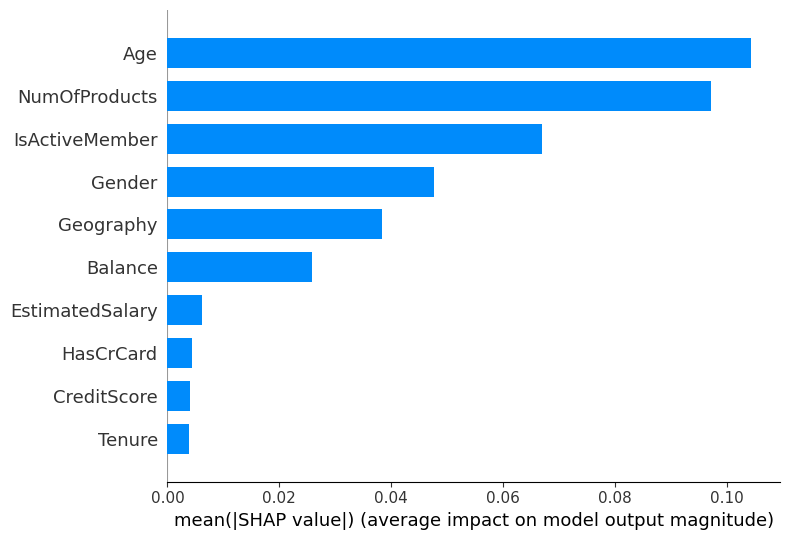

In [4]:
shap.summary_plot(shap_values, x_test, plot_type="bar", feature_names=feature_names)

In [5]:
# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=original_X.columns.tolist())
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)
shap_values_per_feature_sorted

Tenure             0.003911
CreditScore        0.004022
HasCrCard          0.004459
EstimatedSalary    0.006133
Balance            0.025877
Geography          0.038437
Gender             0.047695
IsActiveMember     0.067035
NumOfProducts      0.097241
Age                0.104346
dtype: float64

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Assuming you have already calculated shap_values and x_test

# 最小-最大归一化到 [0, 1] 之间
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

Tenure             0.000000
CreditScore        0.001104
HasCrCard          0.005454
EstimatedSalary    0.022118
Balance            0.218713
Geography          0.343767
Gender             0.435947
IsActiveMember     0.628503
NumOfProducts      0.929256
Age                1.000000
dtype: float64

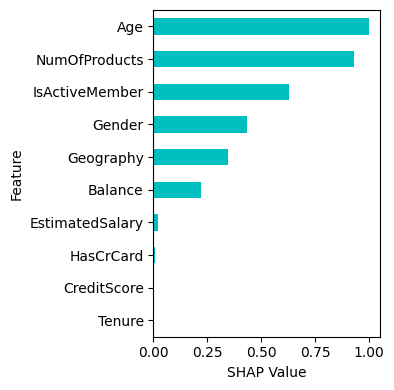

In [7]:
# Create a vertical figure for better spacing
plt.figure(figsize=(4, 4))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized.plot(kind='barh', color='c')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('shap_bank_nn_normalized.eps', format='eps', dpi=300)

plt.show()

In [8]:
import lime
import lime.lime_tabular


explainer = lime.lime_tabular.LimeTabularExplainer(x_train, feature_names=original_X.columns, class_names=['No Diabetes', 'Diabetes'], discretize_continuous=True)

# 定义预测函数
def predict_proba(X):
    proba = model.predict(X)
    return np.hstack((1-proba, proba))

# 选择一个样本进行解释
i = 1
exp = explainer.explain_instance(x_test[i], predict_proba, num_features=10)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 768us/step


In [9]:
# Extract feature values and their weights
feature_values = exp.as_list()

# Sort the features based on their weights
sorted_features = sorted(feature_values, key=lambda x: x[1], reverse=True)

# Print the sorted features and their weights
for feature in sorted_features:
    print(f"Feature: {feature[0]}, Weight: {feature[1]}")

Feature: IsActiveMember <= 0.00, Weight: 0.13375882615755
Feature: 0.50 < Tenure <= 0.70, Weight: 7.76179605249604e-05
Feature: HasCrCard <= 1.00, Weight: 0.0
Feature: 0.32 < CreditScore <= 0.59, Weight: -0.0016105646136366264
Feature: Balance <= 0.00, Weight: -0.002146964856484073
Feature: EstimatedSalary <= 0.34, Weight: -0.0023915735647116266
Feature: Geography <= 0.00, Weight: -0.03853077294997847
Feature: 0.00 < Gender <= 1.00, Weight: -0.09966689281827114
Feature: Age <= 0.25, Weight: -0.14488655732298344
Feature: 0.00 < NumOfProducts <= 1.00, Weight: -0.1976960994422917


In [10]:
# 提取特征值及其权重
feature_values = exp.as_map()[1]

# 根据权重的绝对值对特征进行排序
sorted_features = sorted(feature_values, key=lambda x: abs(x[1]), reverse=True)

# 提取特征名称和权重
features = [original_X.columns[i] for i, _ in sorted_features]
weights = [weight for _, weight in sorted_features]

# 打印排序后的特征及其权重（按绝对值排序）
# print("Sorted features by absolute weight (from largest to smallest):")
for feature, weight in zip(features, weights):
    print(f"Feature: {feature}, Weight: {abs(weight)}")


Feature: NumOfProducts, Weight: 0.1976960994422917
Feature: Age, Weight: 0.14488655732298344
Feature: IsActiveMember, Weight: 0.13375882615755
Feature: Gender, Weight: 0.09966689281827114
Feature: Geography, Weight: 0.03853077294997847
Feature: EstimatedSalary, Weight: 0.0023915735647116266
Feature: Balance, Weight: 0.002146964856484073
Feature: CreditScore, Weight: 0.0016105646136366264
Feature: Tenure, Weight: 7.76179605249604e-05
Feature: HasCrCard, Weight: 0.0


In [11]:
abs_weights = [abs(weight) for weight in weights]
# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]
normalized_weights

[1.0,
 0.7328751438784782,
 0.6765880891676103,
 0.5041419284418625,
 0.19489900437426566,
 0.01209722180386132,
 0.010859925221290371,
 0.00814666864030242,
 0.0003926125034531468,
 0.0]

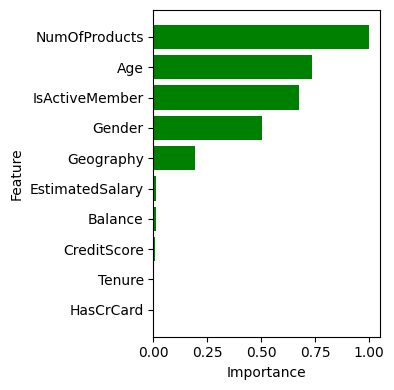

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# 计算绝对权重
abs_weights = [abs(weight) for weight in weights]

# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]

# 绘制归一化后的特征权重条形图
plt.figure(figsize=(4, 4))
plt.barh(features, normalized_weights, color='g')  # 使用归一化后的权重
plt.xlabel('Importance')  # 修改x轴标签
plt.ylabel('Feature')
# plt.title('LIME Feature Weights (Normalized Absolute Values)')  # 修改标题
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('lime_bank_nn_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

In [14]:
from sklearn.inspection import permutation_importance
import numpy as np
result = permutation_importance(model, x_test, y_test, n_repeats=1, random_state=42, scoring='neg_mean_squared_error')

# 打印特征重要性
feature_names = original_X.columns.tolist()
importances = result.importances_mean
std = result.importances_std
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({importances[indices[f]]:.6f})")

1032/1032 ━━━━━━━━━━━━━━━━━━━━ 0s 184us/step
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 0s 188us/step
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 0s 186us/step
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 0s 184us/step
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 0s 184us/step
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 0s 182us/step
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 0s 183us/step
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 0s 183us/step
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 0s 205us/step
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 0s 182us/step
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 0s 181us/step
Feature ranking:
1. feature Age (0.041382)
2. feature NumOfProducts (0.031063)
3. feature IsActiveMember (0.015729)
4. feature Balance (0.010270)
5. feature Geography (0.008685)
6. feature Gender (0.005737)
7. feature EstimatedSalary (0.000254)
8. feature HasCrCard (0.000228)
9. feature CreditScore (0.000139)
10. feature Tenure (0.000055)


In [15]:
# 归一化处理
min_importance = np.min(importances)
max_importance = np.max(importances)
normalized_importances = (importances - min_importance) / (max_importance - min_importance)

# 按归一化后的重要性排序
indices = np.argsort(normalized_importances)[::-1]

# 打印归一化后的特征重要性
print("Feature ranking (normalized importance):")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({normalized_importances[indices[f]]:.6f})")

Feature ranking (normalized importance):
1. feature Age (1.000000)
2. feature NumOfProducts (0.750297)
3. feature IsActiveMember (0.379275)
4. feature Balance (0.247176)
5. feature Geography (0.208835)
6. feature Gender (0.137497)
7. feature EstimatedSalary (0.004832)
8. feature HasCrCard (0.004203)
9. feature CreditScore (0.002046)
10. feature Tenure (0.000000)


In [16]:
# 创建一个数据框来存储特征及其重要性
feature_importance_df = pd.DataFrame({
    'Feature': [feature_names[i] for i in indices],
    'Importance': normalized_importances[indices],
    'Std': std[indices]
})

# 按重要性排序
sorted_feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=True)

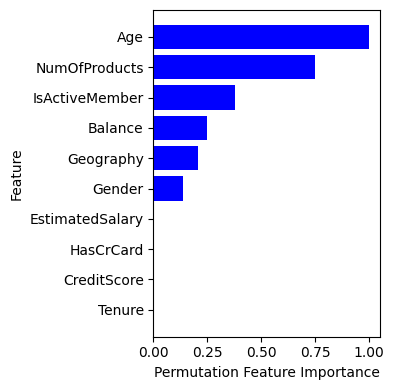

In [17]:
# 画图
plt.figure(figsize=(4, 4))  # 改变图形大小，使其适应竖向显示
plt.barh(sorted_feature_importance_df['Feature'], sorted_feature_importance_df['Importance'], color='b')
plt.ylabel('Feature')
plt.xlabel('Permutation Feature Importance')
# plt.gca().invert_yaxis()  # 反转y轴，使重要性最高的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('Permutation_importance_bank_nn_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()